# Inicialización del Proyecto - Capazeta

Este notebook detalla paso a paso cómo configurar, inicializar y ejecutar el asistente multi-agente **Capazeta**. También incluye la configuración opcional del stack **Wazuh** para utilizar las herramientas de análisis de SOC y Threat Intelligence.

## 1. Clonado e Instalación del Entorno

Capazeta utiliza **[uv](https://docs.astral.sh/uv/)** como gestor de dependencias y entornos virtuales.

```bash
uv venv --python 3.10
source .venv/bin/activate
uv sync
```

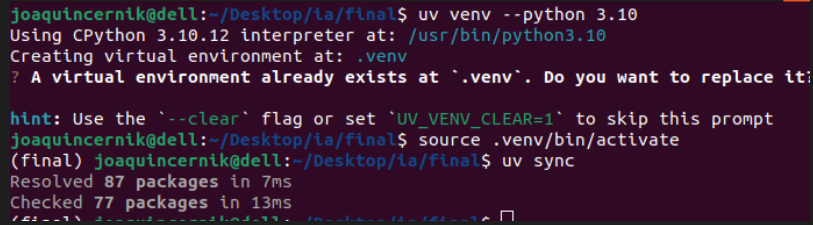

## 2. Configuración de Variables de Entorno

Copiá el archivo de ejemplo `.env.example` y completalo con tus credenciales de API.

In [ ]:
!cp .env.example .env

### Variables principales

Editá el archivo `.env` con los siguientes valores:

```env
# Configuración de API Keys
GOOGLE_API_KEY=tu_api_key_aqui
OPENAI_API_KEY=tu_openai_api_key_aqui
GROQ_API_KEY=tu_groq_api_key_aqui

# Modelo a utilizar (formato: proveedor:modelo)
# Ejemplos:
#   google_genai:gemini-2.5-flash-lite
#   groq:llama-3.1-70b-versatile
#   openai:gpt-4o-mini
MODEL_NAME=google_genai:gemini-2.5-flash-lite

THREAD_ID=capazeta_thread

# Configuración Wazuh (Opcional)
WAZUH_API_URL=https://localhost:55000
WAZUH_API_USER=admin
WAZUH_API_PASSWORD=tu_password_aqui
WAZUH_INDEXER_URL=https://localhost:9200
WAZUH_INDEXER_USER=admin
WAZUH_INDEXER_PASSWORD=tu_password_aqui
WAZUH_VERIFY_SSL=false

# Configuración RAG MITRE ATT&CK
EMBEDDING_MODEL=models/gemini-embedding-001
MITRE_DATA_DIR=data/mitre
```

## 3. Ejecución del Agente

Una vez configuradas las variables de entorno, podés iniciar el CLI interactivo de Capazeta:
```bash
uv run capazeta
```
<div align="center">
  <img src="./img/00_init_proyecto/first-msg.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>
Vemos que se ha incializado correctamente.

Para asegurarnos le preguntamos algo al agente

<div align="center">
  <img src="./img/00_init_proyecto/fist-question.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>

Vemos que funciona correctamente

Para la instalacion del RAG de MITRE ATT&CK se ejecuta 
```bash
uv run python -m capazeta.rag.build --force
```

## 4. Instalación: Wazuh (Docker)

Para aprovechar todas las funcionalidades de los subagentes **SOC / Logs y Eventos** y **Threat Intelligence**, es necesario contar con un stack **Wazuh** levantado localmente.

Wazuh actúa como un *Security Operations Center* (SOC) local, permitiendo la recolección de logs, alertas y el posterior mapeo de las mismas a técnicas del framework **MITRE ATT&CK**.

### 4.1 Levantar Wazuh

La configuración para `single-node` se encuentra incluida en `infra/wazuh/`. Ejecutá los siguientes pasos desde la raíz del proyecto:
```bash
# 1. Ir al directorio de Wazuh (single-node)
cd infra/wazuh

# 2. Aumentar vm.max_map_count (obligatorio en Linux)
sudo sysctl -w vm.max_map_count=262144

# 3. Generar los certificados TLS (solo la primera vez)
docker compose -f generate-indexer-certs.yml run --rm generator

# 4. Levantar el stack en segundo plano
docker compose up -d
```


### 4.2 Acceso al Dashboard

Una vez inicializado el stack (puede tardar ~1 minuto), podés acceder al dashboard desde:

- **URL:** [https://localhost](https://localhost)
- **Usuario/Contraseña:** Por defecto admin y SecretPassword

> **Nota:** Al ser certificados auto-firmados, el navegador mostrará una advertencia de seguridad. Aceptala para continuar.

<div align="center">
  <img src="./img/00_init_proyecto/inicio.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>

### 4.3 Registro de un agente Wazuh

Para que el agente pueda consultar eventos y alertas, es necesario registrar al menos un agente Wazuh:

1. Ingresar al Dashboard de Wazuh → `Wazuh` → `Agents Management` → `Deploy new agent`

<div align="center">
  <img src="./img/wazuh_dashboard.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>


2. Seleccionar el sistema operativo del agente a monitorear

<div align="center">
  <img src="./img/00_init_proyecto/new-agent.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>

3. Asignar la IP del Manager (generalmente `127.0.0.1` o la IP de la máquina donde corre Wazuh)
4. Copiar y ejecutar el comando generado en el agente objetivo

<div align="center">
  <img src="./img/00_init_proyecto/agent-w.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>

Una vez registrado, Capazeta podrá consultarlo utilizando las herramientas `wazuh_list_agents`, `wazuh_search_alerts` y `wazuh_mitre_coverage`.

Tendriamos que ver el agente ya instalado en el dashboard de agentes

<div align="center">
  <img src="./img/00_init_proyecto/check.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>

## 5. Verificación Rápida

Para probar rapidamente esto le podemos preguntar al agente capazeta cuantos agentes tenemos conectados

<div align="center">
  <img src="./img/00_init_proyecto/verify.png" width="700" alt="Prueba de agentes conectados en consola" />
</div>
Vemos que responde de manera correcta